# The fly connectome as a reservoir: handwritten digits, with baselines

**Reservoir computing** sends an input through a fixed, untrained dynamical system and trains
only a linear readout on that system's activity. Here the fixed system is the fly brain
(`flybrain.FlyBrain`, 166,700 neurons, MaleCNS connectome). The task is the 8×8 handwritten digits
from scikit-learn (1,797 images, 10 classes).

The question is whether the **connectome's wiring** helps. So the same pipeline also runs on:

* a **degree-preserving shuffle** of the connectome: every neuron keeps its number of inputs and
  outputs and the sign of its synapses, but the partners are random;
* an **Erdős–Rényi random network** with the same number of neurons and edges;
* a **linear model on the raw pixels**, with no network at all.

**Before running:** `pip install flybrain matplotlib scikit-learn`. The first `FlyBrain()` downloads
the brain (~260 MB) once. The saved outputs below come from an NVIDIA RTX 4060 laptop GPU
(`device="auto"`; the run took 31 minutes, most of it in the connectome runs, where the network is
very active). **CPU works too, but slowly:** at 10-16 ms per step the full notebook takes well over
an hour on a 24-thread laptop CPU. Set `N_DIGITS = 600` (a 600-image subset) for roughly a third of
that. On another device or thread count, individual spikes differ, so expect slightly different numbers.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse
from sklearn.datasets import load_digits

sys.path.insert(0, str(Path.cwd().parent))  # lets a repository clone find flybrain without installing it
import flybrain
from flybrain import FlyBrain, Readout, Trace, run

DEVICE = "auto"        # "cpu" works too, just slower
N_DIGITS = 1797        # all of them; 600 is a quicker subset
SEEDS = [0, 1, 2]      # each seed: its own train/test split, brain noise and random networks

digits = load_digits()
order = np.random.default_rng(1234).permutation(len(digits.target))[:N_DIGITS]
images, labels = digits.data[order] / 16.0, digits.target[order]
print(f"{len(labels)} digits, {images.shape[1]} pixels, classes {np.bincount(labels).tolist()}")

# sensory_input=False removes synapses onto sensory neurons. Without it the olfactory receptor
# neurons excite each other into a runaway loop, fire near their maximum rate at rest, and
# ignore any input (see FlyBrain's docstring).
brain = FlyBrain(device=DEVICE, sensory_input=False)
print(f"flybrain {flybrain.__version__}: {brain.n:,} neurons, {len(brain.indices):,} connections, on {brain.device}")

1797 digits, 64 pixels, classes [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]


flybrain 0.1.0: 166,700 neurons, 25,088,107 connections, on cuda


## Encoding: pixels as odours

We use the fly's own olfactory pathway. There are 53 olfactory receptor neuron (ORN) types, one
per antennal lobe glomerulus. Each one gets one pixel: while a digit is shown, every ORN of that
type (both sides) receives `0.5 V × pixel brightness` per step. 0.5 V was fixed in advance, not
tuned. A fully bright pixel makes its ORNs fire every 2-3 steps.

53 types for 64 pixels: we drop the 11 pixels with the least variance. Those are mostly the
always-blank border. Which pixels to drop is decided on the first seed's training images only,
and the same 53 pixels go to the linear baseline.

The **reservoir** is read from the **Kenyon cells** (4,064 neurons). They are the mushroom body's
expansion layer, two synapses downstream of the ORNs (ORN -> projection neuron -> Kenyon cell).
They are where a fly learns which odours matter. We do not change the network to suit the task.

In [2]:
ct = brain.cell_type.astype(str)
orn_types = sorted(np.unique(ct[np.char.startswith(ct, "ORN_")]))
kc = np.flatnonzero(np.char.startswith(ct, "KC"))
print(f"{len(orn_types)} ORN types ({sum(len(brain.cells([t])) for t in orn_types)} neurons), {len(kc)} Kenyon cells")

ON_STEPS, OFF_STEPS = 5, 3          # each digit: 100 ms on, then 60 ms of blank
SLOT = ON_STEPS + OFF_STEPS
AMOUNT = 0.5


def split(seed, frac=0.75):
    """Stratified train/test split of the N_DIGITS images for this seed."""
    rng = np.random.default_rng(seed)
    train = np.concatenate([rng.permutation(np.flatnonzero(labels == c))[: int(frac * (labels == c).sum())]
                            for c in range(10)])
    return np.sort(train), np.setdiff1d(np.arange(len(labels)), train)


train0, _ = split(SEEDS[0])
pixels = np.sort(np.argsort(-images[train0].var(0))[: len(orn_types)])
dropped = sorted(set(range(64)) - set(pixels.tolist()))
print("pixels dropped (row, col):", [(p // 8, p % 8) for p in dropped])
pixel_rng = np.random.default_rng(0)
orn_cells = [brain.cells([t]) for t in pixel_rng.permutation(orn_types)]   # pixel k -> ORN type k (random pairing)


def encode(t):
    """Inject for step t of the stream: digit t // SLOT, on for the first ON_STEPS steps of its slot."""
    i, within = divmod(t, SLOT)
    if within >= ON_STEPS:
        return []
    x = images[i, pixels]
    return [(orn_cells[k], AMOUNT * x[k]) for k in np.flatnonzero(x > 0)]

53 ORN types (2635 neurons), 4064 Kenyon cells
pixels dropped (row, col): [(0, 0), (1, 0), (2, 0), (3, 0), (3, 7), (4, 0), (4, 7), (5, 0), (5, 7), (6, 0), (7, 0)]


## The networks

The random networks reuse everything except the wiring. Same neurons, same model parameters, same
input neurons, same Kenyon cell indices read out. We rescale every neuron's incoming weights so
its total input strength (the sum of |weights|) matches the connectome's. Only *who connects to
whom* differs.

* **degree-preserving shuffle**: the list of connections keeps every presynaptic neuron and its
  weight (so its sign and out-degree), but the postsynaptic partners are shuffled across all
  edges. In-degrees are preserved too. Duplicate edges that land on the same pair are merged.
* **Erdős–Rényi**: the same number of edges between uniformly random pairs, carrying the
  connectome's weight values in random order.

Swapping the matrix uses `FlyBrain`'s internal arrays. This is a notebook trick, not a public API.

In [3]:
original = sparse.csc_matrix((brain.weights, brain.indices, brain.indptr), shape=(brain.n, brain.n)).tocsr()
row_strength = np.asarray(abs(original).sum(1)).ravel()


def match_input_strength(W):
    W = W.tocsr()
    W.sum_duplicates()
    s = np.asarray(abs(W).sum(1)).ravel()
    scale = np.divide(row_strength, s, out=np.zeros_like(s), where=s > 0)
    W = sparse.diags(scale.astype(np.float32)) @ W
    W.eliminate_zeros()
    return W.tocsr()


def degree_preserving(seed):
    coo = original.tocoo()
    post = np.random.default_rng(seed).permutation(coo.row)
    return match_input_strength(sparse.coo_matrix((coo.data, (post, coo.col)), shape=original.shape))


def erdos_renyi(seed):
    rng = np.random.default_rng(seed)
    m = original.nnz
    pre, post = rng.integers(0, brain.n, m), rng.integers(0, brain.n, m)
    return match_input_strength(sparse.coo_matrix((rng.permutation(original.data), (post, pre)), shape=original.shape))


def use_weights(W):
    """Point the brain at weight matrix W (rows = postsynaptic). Uses FlyBrain internals."""
    W = W.tocsr().astype(np.float32)
    W.sort_indices()
    if brain.device == "cuda":
        from cupyx.scipy import sparse as cusparse
        brain._W = cusparse.csr_matrix(W)
    csc = W.tocsc()
    brain.indptr, brain.indices, brain.weights = csc.indptr, csc.indices, csc.data


NETWORKS = {"connectome": lambda seed: original, "degree-preserving shuffle": degree_preserving,
            "Erdős–Rényi random": erdos_renyi}

## Running the stream

All digits are shown one after another in a fixed order, as one continuous run per network and
seed. A `Trace` (100 ms decay) over the Kenyon cells and over the ORNs themselves is read at the
last step of each digit's slot. That is 2 steps after the digit switched off, enough for the
signal to cross the two synapses from ORN to Kenyon cell.

In [4]:
watch = np.concatenate([kc, np.concatenate(orn_cells)])
sample_steps = np.arange(len(labels)) * SLOT + SLOT - 1
activity, rates = {}, {}

for name, make in NETWORKS.items():
    for seed in SEEDS:
        t0 = time.time()
        use_weights(make(seed))
        brain.reset(seed)
        for _ in range(50):                       # 1 s to settle from silence before the first digit
            brain.step()
        trace = Trace(brain, idx=watch, tau=0.1)
        act = run(brain, len(labels) * SLOT, encode=encode, trace=trace)
        activity[name, seed] = act[sample_steps]
        rates[name, seed] = (act[:, :len(kc)] > 0.5).mean()
        print(f"{name:26s} seed {seed}: {time.time() - t0:5.0f} s, "
              f"Kenyon cells active at a given step: {100 * rates[name, seed]:.1f}%")
use_weights(original)

connectome                 seed 0:   125 s, Kenyon cells active at a given step: 100.0%


connectome                 seed 1:   273 s, Kenyon cells active at a given step: 100.0%


connectome                 seed 2:   421 s, Kenyon cells active at a given step: 100.0%


degree-preserving shuffle  seed 0:   226 s, Kenyon cells active at a given step: 25.9%


degree-preserving shuffle  seed 1:    69 s, Kenyon cells active at a given step: 27.0%


degree-preserving shuffle  seed 2:    69 s, Kenyon cells active at a given step: 26.5%


Erdős–Rényi random         seed 0:    67 s, Kenyon cells active at a given step: 18.6%


Erdős–Rényi random         seed 1:    67 s, Kenyon cells active at a given step: 18.7%


Erdős–Rényi random         seed 2:    68 s, Kenyon cells active at a given step: 18.7%


## Readouts

For each seed: fit `Readout` (ridge regression on one-hot labels, PCA rank and L2 strength chosen
by 5-fold cross-validation on the training set only) and score held-out accuracy (argmax). The
same `Readout` grid is used for every condition, including the raw-pixel baselines.

In [5]:
GRID = dict(components=(20, 60, 200, None), lambdas=(1e-3, 1e-2, 1e-1, 1.0))


def accuracy(X, seed):
    train, test = split(seed)
    r = Readout.fit(X[train], np.eye(10)[labels[train]], kind="ridge", **GRID)
    return float((r.predict(X[test]).argmax(1) == labels[test]).mean())


results = {}
for name in NETWORKS:
    results[f"{name}: Kenyon cells"] = [accuracy(activity[name, s][:, :len(kc)], s) for s in SEEDS]
results["connectome: ORNs (the encoded input)"] = [accuracy(activity["connectome", s][:, len(kc):], s) for s in SEEDS]
results["no network: 53 raw pixels"] = [accuracy(images[:, pixels], s) for s in SEEDS]
results["no network: all 64 raw pixels"] = [accuracy(images, s) for s in SEEDS]
results["chance"] = [0.1] * len(SEEDS)

print(f"{'condition':40s} {'held-out accuracy':>18s}   per seed")
for name, acc in results.items():
    a = np.array(acc)
    print(f"{name:40s} {a.mean():8.3f} ± {a.std(ddof=1) / np.sqrt(len(a)):.3f}      "
          + " ".join(f"{x:.3f}" for x in a))

condition                                 held-out accuracy   per seed
connectome: Kenyon cells                    0.092 ± 0.006      0.099 0.079 0.097
degree-preserving shuffle: Kenyon cells     0.141 ± 0.004      0.145 0.145 0.132
Erdős–Rényi random: Kenyon cells            0.674 ± 0.011      0.659 0.696 0.667
connectome: ORNs (the encoded input)        0.918 ± 0.003      0.912 0.921 0.921
no network: 53 raw pixels                   0.937 ± 0.004      0.930 0.945 0.936
no network: all 64 raw pixels               0.942 ± 0.008      0.930 0.956 0.941
chance                                      0.100 ± 0.000      0.100 0.100 0.100


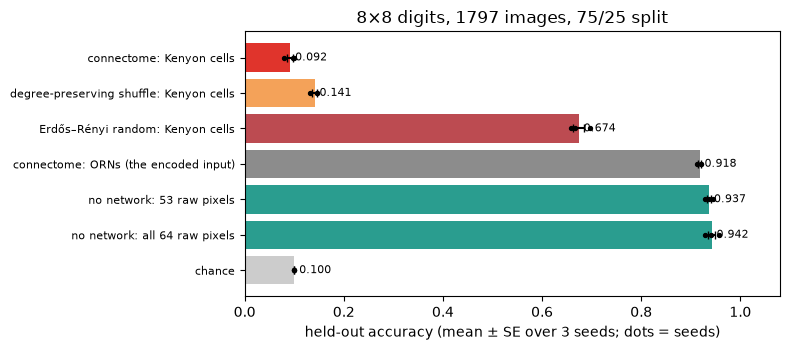

In [6]:
names = list(results)
means = [np.mean(results[n]) for n in names]
ses = [np.std(results[n], ddof=1) / np.sqrt(len(SEEDS)) for n in names]
colors = ["#e0342c", "#f4a259", "#bc4b51", "0.55", "#2a9d8f", "#2a9d8f", "0.8"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(range(len(names))[::-1], means, xerr=ses, color=colors, capsize=3)
for y, (n, m) in enumerate(zip(names, means)):
    ax.text(m + 0.01, len(names) - 1 - y, f"{m:.3f}", va="center", fontsize=8)
    ax.scatter(results[n], [len(names) - 1 - y] * len(SEEDS), s=8, color="k", zorder=3)
ax.set_yticks(range(len(names))[::-1], names, fontsize=8)
ax.set_xlim(0, 1.08)
ax.set_xlabel(f"held-out accuracy (mean ± SE over {len(SEEDS)} seeds; dots = seeds)")
ax.set_title(f"8×8 digits, {len(labels)} images, 75/25 split")
plt.tight_layout()
plt.show()

## What we found

Held-out accuracy, 1,797 digits, 3 seeds (from the outputs above):

| condition | accuracy |
|---|---|
| connectome, Kenyon cells | 0.092 ± 0.006 (chance) |
| degree-preserving shuffle, Kenyon cells | 0.141 ± 0.004 |
| Erdős–Rényi random, Kenyon cells | 0.674 ± 0.011 |
| connectome, ORNs (the encoded input) | 0.918 ± 0.003 |
| no network, 53 raw pixels | 0.937 ± 0.004 |
| no network, all 64 raw pixels | 0.942 ± 0.008 |

**The connectome does not beat the baselines. Read out from its Kenyon cells, it is at chance.**
Both random networks do better, and every network loses to a linear model on the raw pixels.

The run log shows why. In the connectome run, effectively every Kenyon cell spikes every step, for
every digit (100% spiked within the last 3 steps). A population that always does the same thing carries no
information. The digit is still there one layer up: the ORNs give 0.918, close to the raw pixels.
So in this model the information is lost on the way into the mushroom body, which saturates. In
the random networks the same neuron indices fire much less (19-27%), and some of the input gets through.

In a real fly the mushroom body is kept sparse (a few per cent of Kenyon cells per odour) by
feedback inhibition from one giant GABAergic neuron, APL. APL is in the connectome (2 cells), but
with flybrain's shipped parameters it cannot hold 4,064 Kenyon cells down. An earlier study in this
repository on a different task (September 2026) found a sparse code by scaling the existing APL -> Kenyon cell
synapses ×8 and adding -0.6 to every Kenyon cell's input each step. **We did not run that variant
here.** Whether it changes the result is open: try it with the same change applied to all three networks.

Limits of this comparison: one encoding (pixels as ORN types, a fixed 0.5 V gain), one readout
population, one presentation schedule (100 ms on, 60 ms off, read 2 steps after offset), and 3 seeds.
None of these were tuned. A different choice could change the ranking.